<h1 align='center'>Images Negatives</h1>

### Negative Images

A negative image is an image in which every pixel intensity is inverted. Bright pixels becomes dark, dark pixel becomes bright, and colors and replaced by their complementary colors.

**Why is it called a _"negative"_?**

The term comes from photographic film negatives, where:
- Bright parts of the scene appear dark
- Dark parts appear bright.

Printing the negative onto photographic paper produces the original image.

**Formula**

For an 8-bit grayscale image (pixel values range from 0-255):
$$ Negative Pixel = 255 - Original Pixel $$

For example:
| Original | Negative |
| --- | --- |
| 0 (black) | 255 (white) |
| 50 | 205 |
| 128 | 127 |
| 200 | 55 |
| 255 (white) | 0 (black) |

For a color (RGB/BGR) image, the operation is applied independently to each channel:
```text
(B, G, R)
↓
(255-B, 255-G, 255-R)
```

Example:
```text
Original: (20, 150, 240)
Negative: (235, 105, 15)
```

#### Method 1: Using `cv2.bitwise_not()`

- **Colored Image**

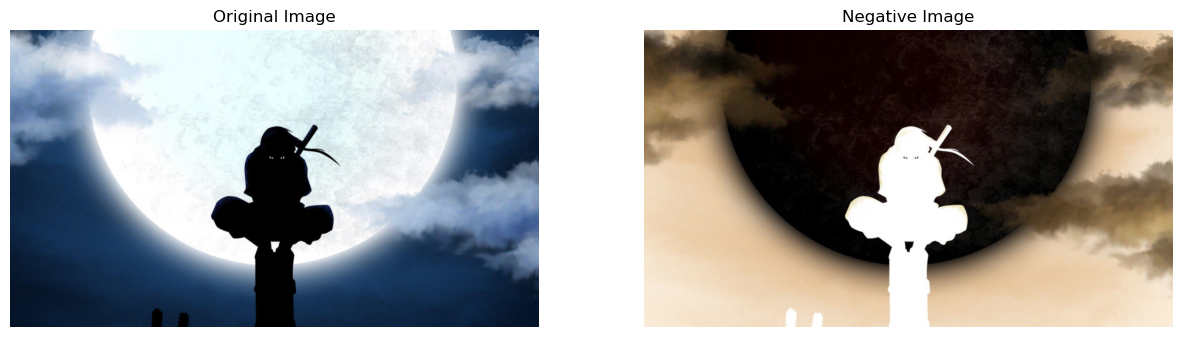

In [1]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('Itachi.jpg')

negative = cv2.bitwise_not(img)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Negative Image")
plt.imshow(cv2.cvtColor(negative, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

- **GrayScale Image**

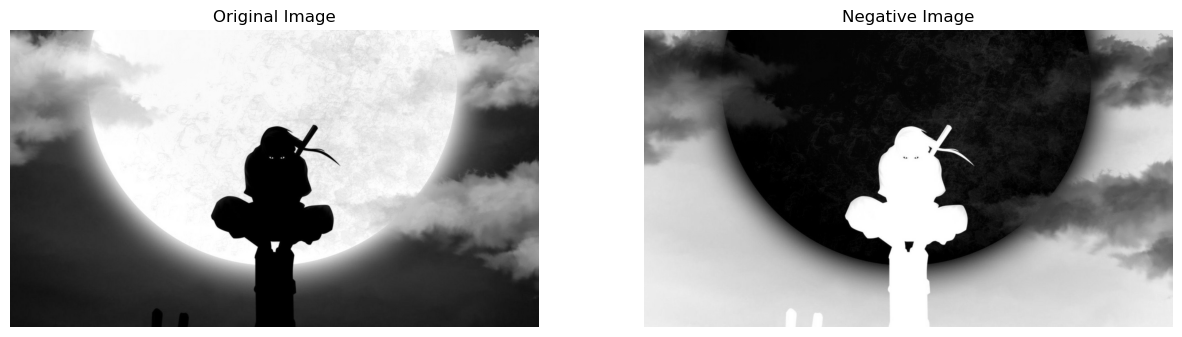

In [8]:
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
negative = cv2.bitwise_not(img)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Negative Image")
plt.imshow(cv2.cvtColor(negative, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()


Why use it:
- Fast 
- Optmized in OpenCV
- Works for grayscale and colored images

---

#### Method 2: Using `numpy`

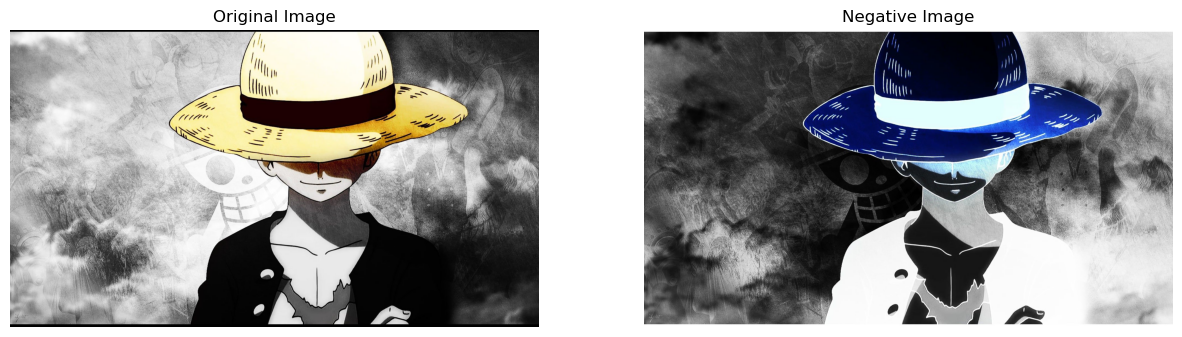

In [10]:
img = cv2.imread('image.jpg')
negative = 255 - img

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Negative Image")
plt.imshow(cv2.cvtColor(negative, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

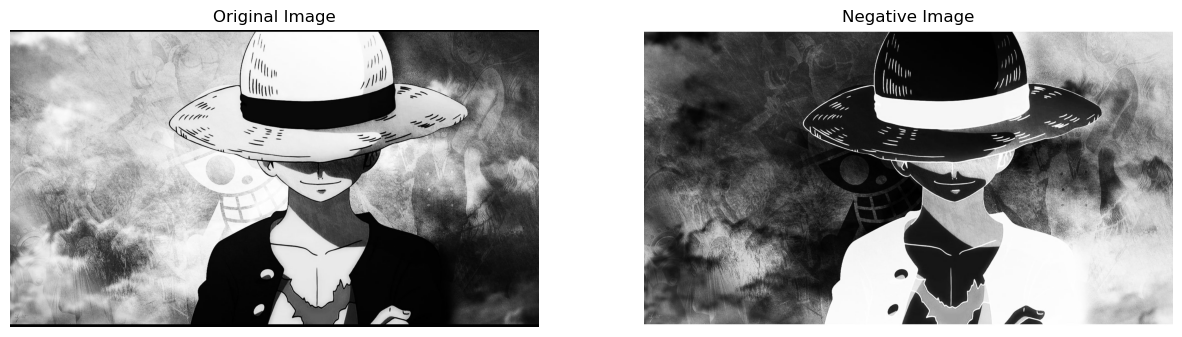

In [12]:
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
negative = 255 - img

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Negative Image")
plt.imshow(cv2.cvtColor(negative, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

This works because NumPy performs the subtraction element-wise.

---

**Applications**

Negative image are useful:
- Enhancing details in medical images (e.g., X-rays).
- Highlighting white or gray details on dark backgrounds.
- Image processing before segmentation or thresholding.
- Artistic image effect.
- Document analysis and OCR in some scenarios.

---

#### General Formula

For an image with L possible intensity levels (0 to L-1):
$$ s = (L - 1) - r $$
Where:
- r = original pixel intensity
- s = negative pixel intensity
- L = number of intensity levels

For an 8-bit image:
- $L$ = 256

So, 
$$ s = 255 - r $$

##### Why does it works?
The transformation is a point processing operation.

Each output pixel depends only on its corresponding input pixel, not neigbouring pixels.

This makes it one of the simplest image enhancement techniques.


---

#### Advantages

- Enhances light objects on dark backgrounds.
- Makes certain details more visible.
- Useful in medical imaging.
- Useful in satellite images.
- Can simplify later image processing steps.

#### Limitations
- Normal photographs often become harder to interpret.
- Colors become unnatural.
- It is mainly useful when the original image has poor visibility of certain features.

---

---

<h1 align='center'>Image Thresholding</h1>

Image Thresholding is a segmentation technique that converts a grayscale image into a binary image by comparing each pixel intensity with a threshold value.

Its main purpose is to separate foreground (objects of interest) from the background.

##### Definition

Given a threshold value T:
$$
g(x,y) = 
\begin{cases} 
255, & f(x,y) \geq T \\ 
0, & f(x,y) < T 
\end{cases}
$$   
Where:
- f(x, y) = Original pixel intensity
- g(x, y) = Output pixel intensity
- T = Threshold value
- 255 = White
- 0 = Black

##### How it works

Suppose threshold is:
```text
T = 100
```
Original pixels:
```text
30  70  120
90  150 220
```
After thesholding:
```text
0   0   255
0   255 255
```

Pixels below 100 becomes black (0). \
Pixels equal to or above 100 becomes white (255).

##### OpenCV Syntax
```Python
ret, output = cv2.threshold(
    src,
    thresh,
    maxValue,
    thresholdType
)
```

Parameters:

- src -> Grayscale image
- thresh -> Threshold value
- maxValue -> Value assigned in binary thresholding (usually 255)
- thresholdType -> Type of thresholding

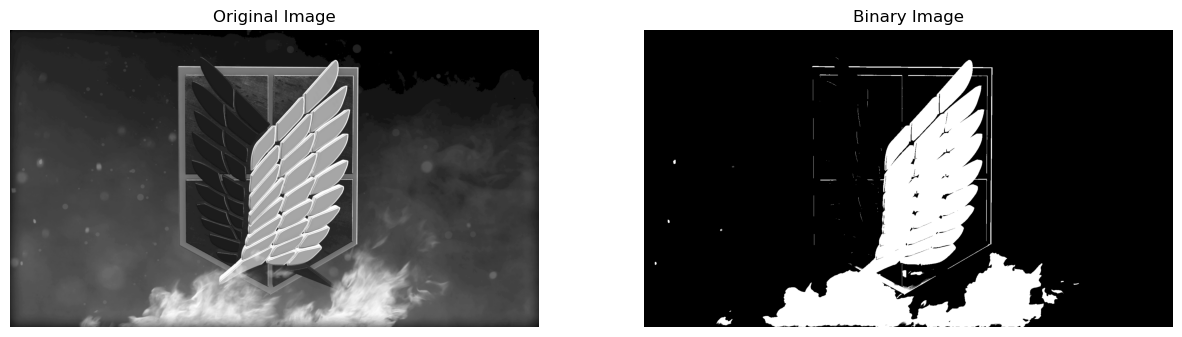

In [16]:
import cv2

img = cv2.imread('aot.png', cv2.IMREAD_GRAYSCALE)

ret, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Binary Image")
plt.imshow(cv2.cvtColor(binary, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

#### Why is thresholding used?
Thresholding simplifies an image by reducing it to two intensity levels.

This makes it easier to:

- Detect objects
- Find boundaries
- Count objects
- Perform OCR
- Perform image segmentation

---

#### Types of Thresholds

#### 1. Binary Threshold

$$
g(x,y) = 
\begin{cases} 
255, & f(x,y) \geq T \\ 
0, & f(x,y) < T 
\end{cases}
$$ 

Example:
```text
Input : 40 90 150 220
Output: 0  0 255 255
```

OpenCV:
```Python
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
```

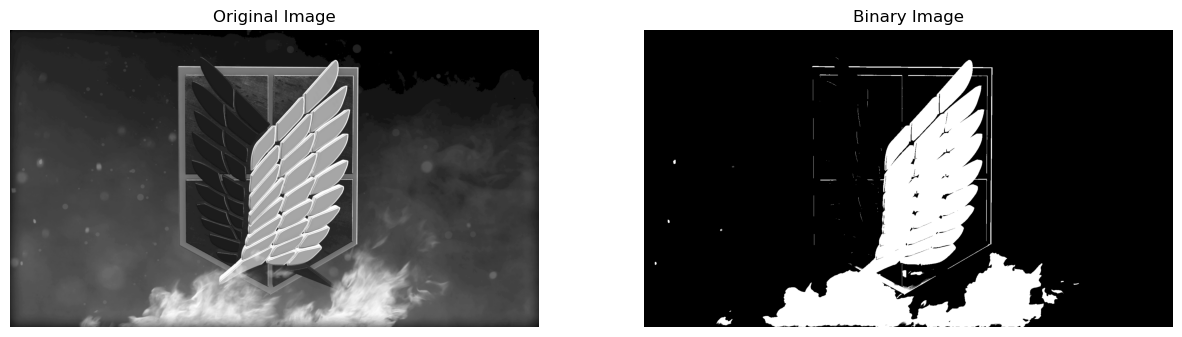

In [17]:
ret, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Binary Image")
plt.imshow(cv2.cvtColor(binary, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

##### 2. Binary Inverse Threshold
$$
g(x,y) = 
\begin{cases} 
0, & f(x,y) \geq T \\ 
255, & f(x,y) < T 
\end{cases}
$$

Example:
```text
Input : 40 90 150 220
Output:255 255 0 0
```

OpenCV:
```Python
ret, thresh = cv2.threshold(img,127,255,cv2.THRESH_BINARY_INV)
```

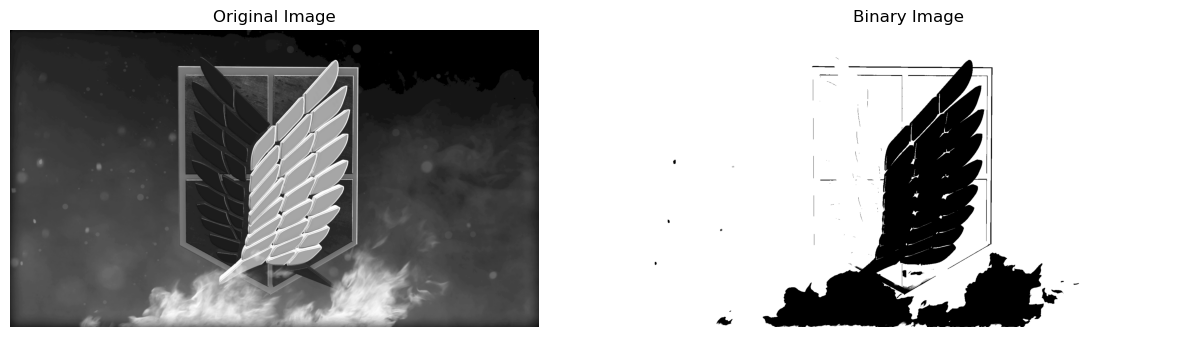

In [18]:
ret, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Binary Image")
plt.imshow(cv2.cvtColor(binary, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

##### 3. Truncate Threshold

Pixels above the threshold become equal to the threshold.

Example:

```text
Threshold = 100

Input
40 90 120 180

Output
40 90 100 100
```

OpenCV:
```Python
cv2.THRESH_TRUNC
```

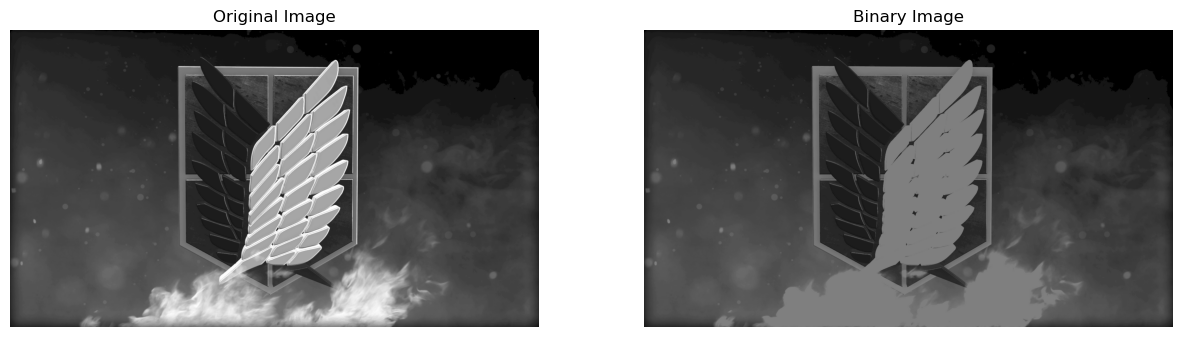

In [19]:
ret, binary = cv2.threshold(img, 127, 255, cv2.THRESH_TRUNC)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Binary Image")
plt.imshow(cv2.cvtColor(binary, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

##### 4. To Zero Threshold

Keep pixels above threshold.

Others become zero.
```text
Example:

Input
40 90 120 180

Output
0 0 120 180
```
OpenCV:
```Python
cv2.THRESH_TOZERO
```

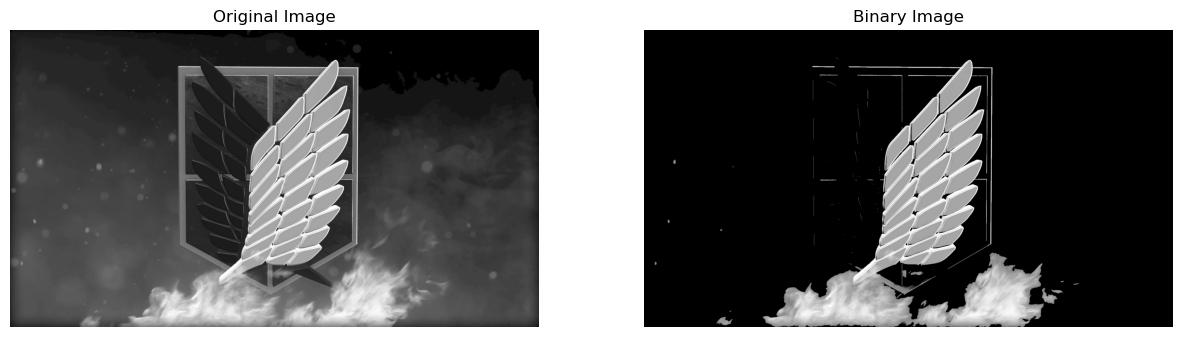

In [20]:
ret, binary = cv2.threshold(img, 127, 255, cv2.THRESH_TOZERO)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Binary Image")
plt.imshow(cv2.cvtColor(binary, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

##### 5. To Zero Inverse

Keep pixels below threshold.

Others become zero.

Example:
```text
Input
40 90 120 180

Output
40 90 0 0
```
OpenCV:
```Python
cv2.THRESH_TOZERO_INV
```

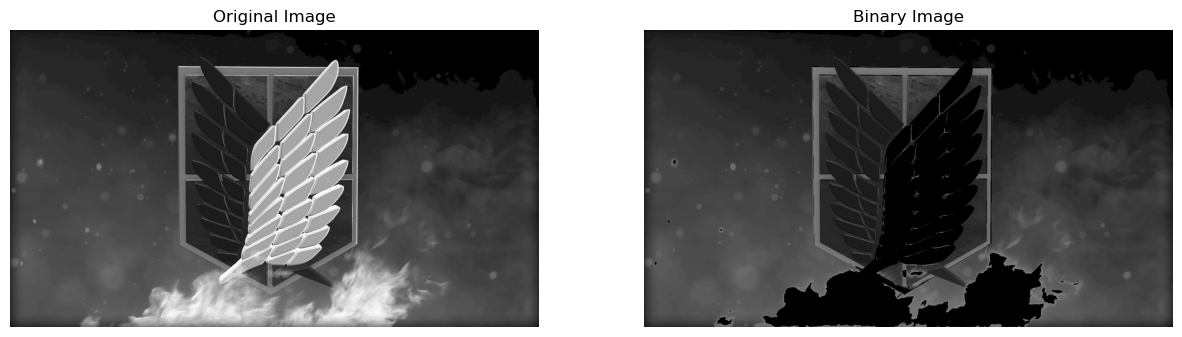

In [21]:
ret, binary = cv2.threshold(img, 127, 255, cv2.THRESH_TOZERO_INV)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Binary Image")
plt.imshow(cv2.cvtColor(binary, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()

---

#### Summary of Threshold Types

| Type            | Below Threshold | Above Threshold |
| --------------- | --------------- | --------------- |
| Binary          | 0               | Max (255)       |
| Binary Inverse  | Max (255)       | 0               |
| Truncate        | Original        | Threshold value |
| To Zero         | 0               | Original        |
| To Zero Inverse | Original        | 0               |
